In [ ]:
 from sympy import symbols, solve, lambdify, cos, sin, rad, pi, sqrt
from sympy.physics.mechanics import ReferenceFrame, dynamicsymbols

from scipy.integrate import odeint

import numpy as np

import matplotlib.pyplot as plt

### List of Components

#### Motor(s)

Option 1: [Blue Robotics T200](https://bluerobotics.com/store/thrusters/t100-t200-thrusters/t200-thruster-r2-rp/)

| Feature | Specification |
| :--- | :--- |
| Price | 230 USD |
| Force @ 12V | 36 N |
| Current Draw @ 12 V | 16.91 A |
| Mass | 0.427 kg |


Option 2: [Blue Robotics T500](https://bluerobotics.com/store/thrusters/t100-t200-thrusters/t500-thruster/)
| Feature | Specification |
| :--- | :--- |
| Price | 790 USD |
| Force @ 12V | 58.8 N |
| Current Draw @ 12 V | 16.91 A  or 16.07|
| Mass | 1.157 kg |

#### Stearing Mechanism

Option 1: [Stepper Motor](https://www.omc-stepperonline.com/e-series-nema-17-bipolar-42ncm-59-49oz-in-1-5a-42x42x38mm-4-wires-w-1m-cable-connector-17he15-1504s?search=17HE15)
| Feature | Specification |
| :--- | :--- |
| Price | 4.72 USD |
| Holding Torque | 42 Ncm |
| Mass | 0.280 kg |

#### Batteries
Option 1: [18650 li-ion cell](https://www.amazon.com/Rechargeable-Battery-Batteries-Flashlights-Headlight/dp/B0FH9YLSVF/ref=sr_1_3?crid=35XHKN8G9HEGV&dib=eyJ2IjoiMSJ9.3eqzkG4CoQWKRy6RsRoZlnwq_TFPk1FHdRVeAqaru1ue-61RI7HH2Pm5K1HGku5phawVUl0tsk2SVXmRRrnFi1CI3tg22hdqPksC3eVZJFL4_UIVQM-wVLTk67ZTtYmMxMRn77pY5KBvFOO0OSfMiltx1g_j6GM1p_QX5urKklDMxgPlwQwuUJsXZLUpkaJc.aKH6c6J7DoB1yc3GOnboXBIfd4kVc6DTpVu5VmyEPO8&dib_tag=se&keywords=18650%2Bli-ion%2Bbattery&qid=1756877929&refinements=p_72%3A1248903011&rnid=1248901011&s=hpc&sprefix=18650%2Bli-ion%2B%2Caps%2C386&sr=1-3&th=1)

In a 3S (11.1V) or 4S (14.8V) Configuration.

| Feature | Specification |
| :--- | :--- |
| Price | 4.65 USD |
| Capacity | 3500mAh |
| Mass | 50 g |

For 1h of operation around 15 batteries are needed (750g per motor).

### Model #1

In [ ]:
x, y, theta_1, theta_2 = dynamicsymbols('x, y, theta_1, theta_2')
t, l_motor, l_battery = symbols('t, l_motor, l_battery')

N = ReferenceFrame('N')
A = N.orientnew('A', 'Axis', (-pi/2 + theta_1, N.z))
B = A.orientnew('B', 'Axis', (theta_2, A.z))

r_center = x*N.x + y*N.y

r_motor = r_center + l_motor*A.x
r_battery = r_center - l_battery*A.x

In [ ]:
m_motor, m_battery = symbols('m_motor, m_battery')

total_mass = m_motor + m_battery
r_center_mass = (r_motor*m_motor + r_battery*m_battery)/total_mass
v_center_mass = r_center_mass.dt(N)
a_center_mass = v_center_mass.dt(N)

In [ ]:
F_in, I = symbols('F_in, I')

Feq = -F_in*B.x - total_mass*a_center_mass
Meq = (r_motor - r_center_mass).cross(-F_in*B.x) - I*theta_1.diff(t,2)*N.z

In [ ]:
Feqx = Feq.dot(N.x)
Feqy = Feq.dot(N.y)

Meqz = Meq.dot(N.z)

eqs = [Feqx, Feqy, Meqz]
vars = [x.diff(t,2), y.diff(t,2), theta_1.diff(t,2)]

sols = solve(eqs, vars)
sols

{Derivative(theta_1(t), (t, 2)): -F_in*l_battery*m_battery*sin(theta_2(t))/(I*m_battery + I*m_motor) - F_in*l_motor*m_battery*sin(theta_2(t))/(I*m_battery + I*m_motor),
 Derivative(x(t), (t, 2)): -F_in*I*m_battery*sin(theta_1(t))*cos(theta_2(t))/(I*m_battery**2 + 2*I*m_battery*m_motor + I*m_motor**2) - F_in*I*m_battery*sin(theta_2(t))*cos(theta_1(t))/(I*m_battery**2 + 2*I*m_battery*m_motor + I*m_motor**2) - F_in*I*m_motor*sin(theta_1(t))*cos(theta_2(t))/(I*m_battery**2 + 2*I*m_battery*m_motor + I*m_motor**2) - F_in*I*m_motor*sin(theta_2(t))*cos(theta_1(t))/(I*m_battery**2 + 2*I*m_battery*m_motor + I*m_motor**2) - F_in*l_battery**2*m_battery**2*sin(theta_2(t))*cos(theta_1(t))/(I*m_battery**2 + 2*I*m_battery*m_motor + I*m_motor**2) - F_in*l_battery*l_motor*m_battery**2*sin(theta_2(t))*cos(theta_1(t))/(I*m_battery**2 + 2*I*m_battery*m_motor + I*m_motor**2) + F_in*l_battery*l_motor*m_battery*m_motor*sin(theta_2(t))*cos(theta_1(t))/(I*m_battery**2 + 2*I*m_battery*m_motor + I*m_motor**2) + F

In [ ]:
moment_of_inertia = m_motor*(r_motor - r_center_mass).magnitude()**2  + m_battery*(r_center_mass - r_center_mass).magnitude()**2
paramsT200 = {m_motor:0.427 + 0.28, m_battery:0.75, l_motor:1, l_battery:1, I:moment_of_inertia}

xddot = lambdify([(x, y, theta_1, x.diff(t), y.diff(t), theta_1.diff(t)), F_in,  theta_2], sols[x.diff(t,2)].subs(paramsT200))
yddot = lambdify([(x, y, theta_1, x.diff(t), y.diff(t), theta_1.diff(t)), F_in, theta_2], sols[y.diff(t,2)].subs(paramsT200))
theta_1ddot = lambdify([(x, y, theta_1, x.diff(t), y.diff(t), theta_1.diff(t)), F_in, theta_2], sols[theta_1.diff(t,2)].subs(paramsT200))

In [ ]:
def odefun(q, t=None, F_in=0, theta_2=0):
  qdot = np.zeros_like(q)
  qdot[:3] = q[3:]
  qdot[3] = xddot(q, F_in, theta_2)
  qdot[4] = yddot(q, F_in, theta_2)
  qdot[5] = theta_1ddot(q, F_in,theta_2)
  return qdot

In [ ]:
time = np.linspace(0, 10, 5000)
q0 = np.array([0, 0, 0, 0, 0, 0])
q_listT200 = odeint(odefun, q0, time, args=(36, 0))

time_rotation = np.linspace(0, 5, 5000)
q_listT200_rotation = odeint(odefun, q0, time_rotation, args=(36, np.deg2rad(90)))

In [ ]:
paramsT500 = {m_motor:1.157 + 0.28, m_battery:0.75, l_motor:1, l_battery:1, I:moment_of_inertia}

xddot = lambdify([(x, y, theta_1, x.diff(t), y.diff(t), theta_1.diff(t)), F_in,  theta_2], sols[x.diff(t,2)].subs(paramsT500))
yddot = lambdify([(x, y, theta_1, x.diff(t), y.diff(t), theta_1.diff(t)), F_in, theta_2], sols[y.diff(t,2)].subs(paramsT500))
theta_1ddot = lambdify([(x, y, theta_1, x.diff(t), y.diff(t), theta_1.diff(t)), F_in, theta_2], sols[theta_1.diff(t,2)].subs(paramsT500))

In [ ]:
q0 = np.array([0, 0, 0, 0, 0, 0])
q_listT500 = odeint(odefun, q0, time, args=(58.8, 0))
q_listT500_rotation = odeint(odefun, q0, time_rotation, args=(56.8, np.deg2rad(90)))

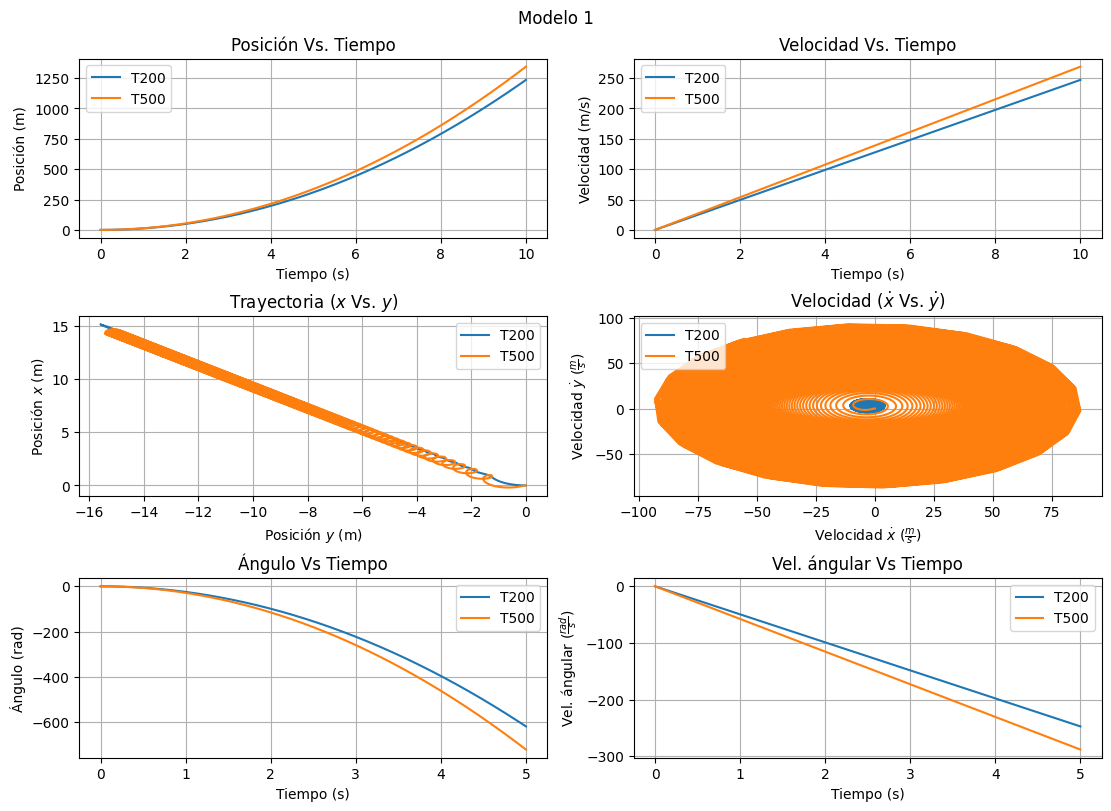

In [ ]:
fig, ax = plt.subplots(3, 2, layout='constrained', figsize=(11, 8))

fig.suptitle('Modelo 1')

ax[0,0].plot(time, q_listT200[:, 1], label='T200')
ax[0,0].plot(time, q_listT500[:, 1], label='T500')
ax[0,0].set(title='Posición Vs. Tiempo', ylabel='Posición (m)', xlabel='Tiempo (s)')
ax[0,0].legend()
ax[0,0].grid()


ax[0, 1].plot(time, q_listT200[:, 4], label='T200')
ax[0, 1].plot(time, q_listT500[:, 4], label='T500')
ax[0, 1].set(title='Velocidad Vs. Tiempo', ylabel='Velocidad (m/s)', xlabel='Tiempo (s)')
ax[0, 1].legend()
ax[0, 1].grid()

ax[1,0].plot(q_listT200_rotation[:, 0], q_listT200_rotation[:, 1], label='T200')
ax[1,0].plot(q_listT500_rotation[:, 0], q_listT500_rotation[:, 1], label='T500')
ax[1,0].set(title='Trayectoria ($x$ Vs. $y$)', ylabel='Posición $x$ (m)', xlabel='Posición $y$ (m)')
ax[1,0].legend()
ax[1,0].grid()

ax[1,1].plot(q_listT200_rotation[:, 3], q_listT200_rotation[:, 4], label='T200')
ax[1,1].plot(q_listT500_rotation[:, 3], q_listT500_rotation[:, 4], label='T500')
ax[1,1].set(title=r'Velocidad ($\dot{x}$ Vs. $\dot{y}$)', xlabel=r'Velocidad $\dot{x}$ ($\frac{m}{s}$)', ylabel=r'Velocidad $\dot{y}$ ($\frac{m}{s}$)')
ax[1,1].legend()
ax[1,1].grid()


ax[2,0].plot(time_rotation, q_listT200_rotation[:, 2], label='T200')
ax[2,0].plot(time_rotation, q_listT500_rotation[:, 2], label='T500')
ax[2,0].set(title=r'Ángulo Vs Tiempo', xlabel=r'Tiempo (s)', ylabel=r'Ángulo (rad)')
ax[2,0].legend()
ax[2,0].grid()

ax[2,1].plot(time_rotation, q_listT200_rotation[:, 5], label='T200')
ax[2,1].plot(time_rotation, q_listT500_rotation[:, 5], label='T500')
ax[2,1].set(title=r'Vel. ángular Vs Tiempo', xlabel=r'Tiempo (s)', ylabel=r'Vel. ángular ($\frac{rad}{s}$)')
ax[2,1].legend()
ax[2,1].grid()


plt.show()

### Model #2

In [ ]:
x, y, theta = dynamicsymbols('x, y, theta')

t, l_motor, l_battery, l_offset = symbols('t, l_motor, l_battery, l_offset')

N = ReferenceFrame('N')
A = N.orientnew('A', 'Axis', (-pi/2 + theta, N.z))
M_1 = A.orientnew('M_1', 'Axis', (rad(45), A.z))
M_2 = A.orientnew('M_2', 'Axis', (rad(-45), A.z))

r_center = x*N.x + y*N.y

r_motor_1 = r_center + l_offset*A.x + l_motor*M_1.x
r_motor_2 = r_center + l_offset*A.x + l_motor*M_2.x
r_battery = r_center - l_battery*A.x

In [ ]:
m_motor, m_battery = symbols('m_motor, m_battery')

total_mass = 2*m_motor + m_battery
r_center_mass = (r_motor_1*m_motor + r_motor_2*m_motor + r_battery*m_battery)/total_mass
v_center_mass = r_center_mass.dt(N)
a_center_mass = v_center_mass.dt(N)

In [ ]:
F_1, F_2, I = symbols('F_1, F_2, I')

Feq = -F_1*M_1.x -F_2*M_2.x - total_mass*a_center_mass
Meq = (r_motor_1 - r_center_mass).cross(-F_1*M_1.x) + (r_motor_2 - r_center_mass).cross(-F_2*M_2.x) -I*theta.diff(t,2)*N.z

In [ ]:
Feqx = Feq.dot(N.x)
Feqy = Feq.dot(N.y)

Meqz = Meq.dot(N.z)

eqs = [Feqx, Feqy, Meqz]
vars = [x.diff(t,2), y.diff(t,2), theta.diff(t,2)]

sols = solve(eqs, vars)
sols

{Derivative(theta(t), (t, 2)): -sqrt(2)*F_1*l_battery*m_battery/(2*I*m_battery + 4*I*m_motor) + 2*F_1*l_motor*m_motor/(2*I*m_battery + 4*I*m_motor) - sqrt(2)*F_1*l_offset*m_battery/(2*I*m_battery + 4*I*m_motor) + sqrt(2)*F_2*l_battery*m_battery/(2*I*m_battery + 4*I*m_motor) - 2*F_2*l_motor*m_motor/(2*I*m_battery + 4*I*m_motor) + sqrt(2)*F_2*l_offset*m_battery/(2*I*m_battery + 4*I*m_motor),
 Derivative(x(t), (t, 2)): -sqrt(2)*F_1*I*m_battery*sin(theta(t))/(2*I*m_battery**2 + 8*I*m_battery*m_motor + 8*I*m_motor**2) - sqrt(2)*F_1*I*m_battery*cos(theta(t))/(2*I*m_battery**2 + 8*I*m_battery*m_motor + 8*I*m_motor**2) - 2*sqrt(2)*F_1*I*m_motor*sin(theta(t))/(2*I*m_battery**2 + 8*I*m_battery*m_motor + 8*I*m_motor**2) - 2*sqrt(2)*F_1*I*m_motor*cos(theta(t))/(2*I*m_battery**2 + 8*I*m_battery*m_motor + 8*I*m_motor**2) - sqrt(2)*F_1*l_battery**2*m_battery**2*cos(theta(t))/(2*I*m_battery**2 + 8*I*m_battery*m_motor + 8*I*m_motor**2) + 4*F_1*l_battery*l_motor*m_battery*m_motor*cos(theta(t))/(2*I*m_ba

In [ ]:
moment_of_inertia = m_motor*(r_motor_1 - r_center_mass).magnitude()**2  + m_motor*(r_motor_2 - r_center_mass).magnitude()**2 + m_battery*(r_battery - r_center_mass).magnitude()**2
paramsT200 = {m_motor:0.427, m_battery:0.750*2, l_motor:1, l_battery:1, l_offset:1, I:moment_of_inertia}

xddot = lambdify([(x, y, theta, x.diff(t), y.diff(t), theta.diff(t)), F_1, F_2], sols[x.diff(t,2)].simplify().subs(paramsT200))
yddot = lambdify([(x, y, theta, x.diff(t), y.diff(t), theta.diff(t)), F_1, F_2], sols[y.diff(t,2)].simplify().subs(paramsT200))
thetaddot = lambdify([(x, y, theta, x.diff(t), y.diff(t), theta.diff(t)), F_1, F_2], sols[theta.diff(t,2)].simplify().subs(paramsT200))

In [ ]:
def odefun(q, t=None, F_1=0, F_2=0):
  qdot = np.zeros_like(q)
  qdot[:3] = q[3:]
  qdot[3] = xddot(q, F_1, F_2)
  qdot[4] = yddot(q, F_1, F_2)
  qdot[5] = thetaddot(q, F_1, F_2)
  return qdot

In [ ]:
time = np.linspace(0, 10, 5000)
q0 = np.array([0, 0, 0, 0, 0, 0])
q_listT200 = odeint(odefun, q0, time, args=(36,36))

time_rotation = np.linspace(0, 5, 5000)
q_listT200_rotation = odeint(odefun, q0, time_rotation, args=(36,-36))

In [ ]:
paramsT500 = {m_motor:1.157, m_battery:0.750*2, l_motor:1, l_battery:1, l_offset:1, I:moment_of_inertia}

xddot = lambdify([(x, y, theta, x.diff(t), y.diff(t), theta.diff(t)), F_1, F_2], sols[x.diff(t,2)].simplify().subs(paramsT200))
yddot = lambdify([(x, y, theta, x.diff(t), y.diff(t), theta.diff(t)), F_1, F_2], sols[y.diff(t,2)].simplify().subs(paramsT200))
thetaddot = lambdify([(x, y, theta, x.diff(t), y.diff(t), theta.diff(t)), F_1, F_2], sols[theta.diff(t,2)].simplify().subs(paramsT200))

In [ ]:
q0 = np.array([0, 0, 0, 0, 0, 0])
q_listT500 = odeint(odefun, q0, time, args=(58.8,58.8))
q_listT500_rotation = odeint(odefun, q0, time_rotation, args=(58.8,-58.8))

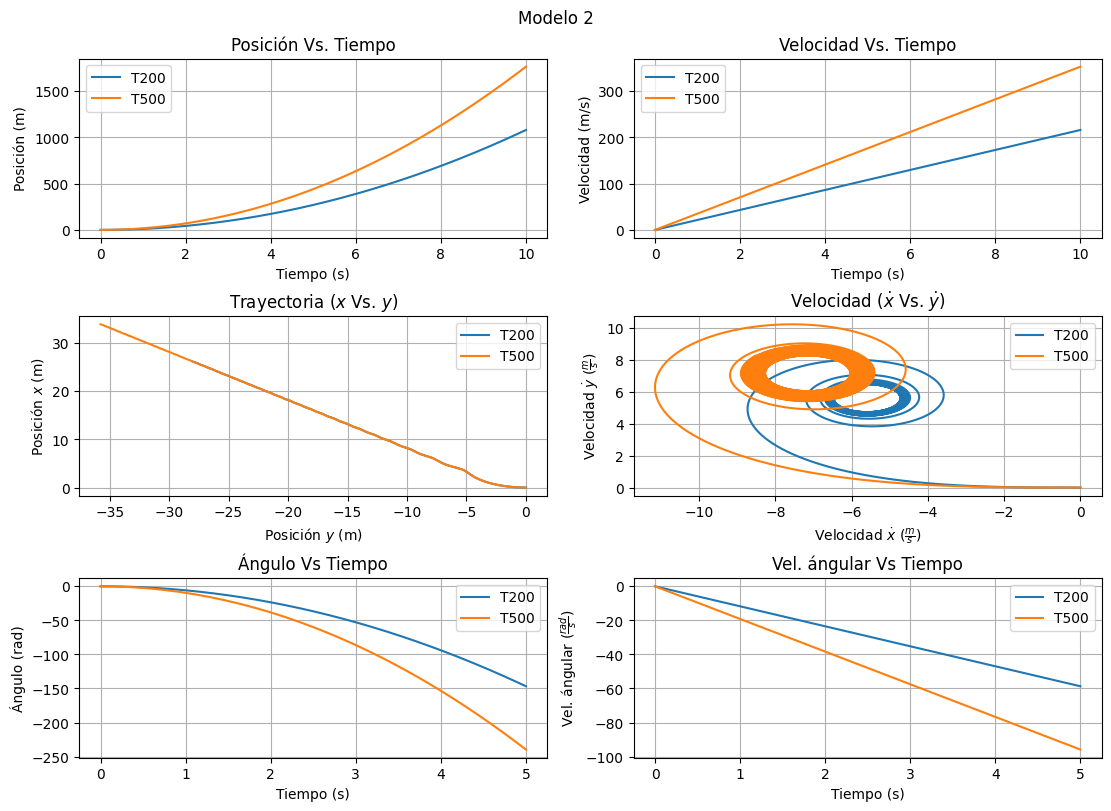

In [ ]:
fig, ax = plt.subplots(3, 2, layout='constrained', figsize=(11, 8))

fig.suptitle('Modelo 2')

ax[0,0].plot(time, q_listT200[:, 1], label='T200')
ax[0,0].plot(time, q_listT500[:, 1], label='T500')
ax[0,0].set(title='Posición Vs. Tiempo', ylabel='Posición (m)', xlabel='Tiempo (s)')
ax[0,0].legend()
ax[0,0].grid()

ax[0, 1].plot(time, q_listT200[:, 4], label='T200')
ax[0, 1].plot(time, q_listT500[:, 4], label='T500')
ax[0, 1].set(title='Velocidad Vs. Tiempo', ylabel='Velocidad (m/s)', xlabel='Tiempo (s)')
ax[0, 1].legend()
ax[0, 1].grid()

ax[1,0].plot(q_listT200_rotation[:, 0], q_listT200_rotation[:, 1], label='T200')
ax[1,0].plot(q_listT500_rotation[:, 0], q_listT500_rotation[:, 1], label='T500')
ax[1,0].set(title='Trayectoria ($x$ Vs. $y$)', ylabel='Posición $x$ (m)', xlabel='Posición $y$ (m)')
ax[1,0].legend()
ax[1,0].grid()

ax[1,1].plot(q_listT200_rotation[:, 3], q_listT200_rotation[:, 4], label='T200')
ax[1,1].plot(q_listT500_rotation[:, 3], q_listT500_rotation[:, 4], label='T500')
ax[1,1].set(title=r'Velocidad ($\dot{x}$ Vs. $\dot{y}$)', xlabel=r'Velocidad $\dot{x}$ ($\frac{m}{s}$)', ylabel=r'Velocidad $\dot{y}$ ($\frac{m}{s}$)')
ax[1,1].legend()
ax[1,1].grid()

ax[2,0].plot(time_rotation, q_listT200_rotation[:, 2], label='T200')
ax[2,0].plot(time_rotation, q_listT500_rotation[:, 2], label='T500')
ax[2,0].set(title=r'Ángulo Vs Tiempo', xlabel=r'Tiempo (s)', ylabel=r'Ángulo (rad)')
ax[2,0].legend()
ax[2,0].grid()

ax[2,1].plot(time_rotation, q_listT200_rotation[:, 5], label='T200')
ax[2,1].plot(time_rotation, q_listT500_rotation[:, 5], label='T500')
ax[2,1].set(title=r'Vel. ángular Vs Tiempo', xlabel=r'Tiempo (s)', ylabel=r'Vel. ángular ($\frac{rad}{s}$)')
ax[2,1].legend()
ax[2,1].grid()

plt.show()

### Model #3

In [ ]:
x, y, theta = dynamicsymbols('x, y, theta')

t, l_motor, l_battery, l_offset, beta_1, beta_2 = symbols('t, l_motor, l_battery, l_offset, beta_1, beta_2')

N = ReferenceFrame('N')
A = N.orientnew('A', 'Axis', (-pi/2 + theta, N.z))

M_1 = A.orientnew('M_1', 'Axis', (rad(45), A.z))
D_1 = M_1.orientnew('D_1','Axis', (beta_1, M_1.z))

M_2 = A.orientnew('M_2', 'Axis', (rad(-45), A.z))
D_2 = M_2.orientnew('D_2','Axis', (beta_2, M_2.z))

r_center = x*N.x + y*N.y

r_motor_1 = r_center + l_offset*A.x + l_motor*M_1.x
r_motor_2 = r_center + l_offset*A.x + l_motor*M_2.x
r_battery = r_center - l_battery*A.x

In [ ]:
m_motor, m_battery = symbols('m_motor, m_battery')

total_mass = 2*m_motor + m_battery
r_center_mass = (r_motor_1*m_motor + r_motor_2*m_motor + r_battery*m_battery)/total_mass
v_center_mass = r_center_mass.dt(N)
a_center_mass = v_center_mass.dt(N)

In [ ]:
F_1, F_2, I = symbols('F_1, F_2, I')

Feq = -F_1*D_1.x - F_2*D_2.x - total_mass*a_center_mass
Meq = (r_motor_1 - r_center_mass).cross(-F_1*D_1.x) + (r_motor_2 - r_center_mass).cross(-F_2*D_2.x) -I*theta.diff(t,2)*N.z

In [ ]:
Feqx = Feq.dot(N.x)
Feqy = Feq.dot(N.y)

Meqz = Meq.dot(N.z)

eqs = [Feqx, Feqy, Meqz]
vars = [x.diff(t,2), y.diff(t,2), theta.diff(t,2)]

sols = solve(eqs, vars)
sols

{Derivative(theta(t), (t, 2)): -sqrt(2)*F_1*l_battery*m_battery*sin(beta_1)/(2*I*m_battery + 4*I*m_motor) - sqrt(2)*F_1*l_battery*m_battery*cos(beta_1)/(2*I*m_battery + 4*I*m_motor) - 2*F_1*l_motor*m_battery*sin(beta_1)/(2*I*m_battery + 4*I*m_motor) - 2*F_1*l_motor*m_motor*sin(beta_1)/(2*I*m_battery + 4*I*m_motor) + 2*F_1*l_motor*m_motor*cos(beta_1)/(2*I*m_battery + 4*I*m_motor) - sqrt(2)*F_1*l_offset*m_battery*sin(beta_1)/(2*I*m_battery + 4*I*m_motor) - sqrt(2)*F_1*l_offset*m_battery*cos(beta_1)/(2*I*m_battery + 4*I*m_motor) - sqrt(2)*F_2*l_battery*m_battery*sin(beta_2)/(2*I*m_battery + 4*I*m_motor) + sqrt(2)*F_2*l_battery*m_battery*cos(beta_2)/(2*I*m_battery + 4*I*m_motor) - 2*F_2*l_motor*m_battery*sin(beta_2)/(2*I*m_battery + 4*I*m_motor) - 2*F_2*l_motor*m_motor*sin(beta_2)/(2*I*m_battery + 4*I*m_motor) - 2*F_2*l_motor*m_motor*cos(beta_2)/(2*I*m_battery + 4*I*m_motor) - sqrt(2)*F_2*l_offset*m_battery*sin(beta_2)/(2*I*m_battery + 4*I*m_motor) + sqrt(2)*F_2*l_offset*m_battery*cos(beta

In [ ]:
moment_of_inertia = m_motor*(r_motor_1 - r_center_mass).magnitude()**2  + m_motor*(r_motor_2 - r_center_mass).magnitude()**2 + m_battery*(r_battery - r_center_mass).magnitude()**2
paramsT200 = {m_motor:0.427 + 0.28, m_battery:0.75*2, l_motor:1, l_battery:1, l_offset:1, I:moment_of_inertia}

xddot = lambdify([(x, y, theta, x.diff(t), y.diff(t), theta.diff(t)), F_1, beta_1, F_2, beta_2], sols[x.diff(t,2)].simplify().subs(paramsT200))
yddot = lambdify([(x, y, theta, x.diff(t), y.diff(t), theta.diff(t)), F_1, beta_1, F_2, beta_2], sols[y.diff(t,2)].simplify().subs(paramsT200))
thetaddot = lambdify([(x, y, theta, x.diff(t), y.diff(t), theta.diff(t)), F_1, beta_1, F_2, beta_2], sols[theta.diff(t,2)].simplify().subs(paramsT200))

In [ ]:
def odefun(q, t=None, F_1=0, beta_1=0, F_2=0, beta_2=0):
  qdot = np.zeros_like(q)
  qdot[:3] = q[3:]
  qdot[3] = xddot(q, F_1, beta_1, F_2, beta_2)
  qdot[4] = yddot(q, F_1, beta_1, F_2, beta_2)
  qdot[5] = thetaddot(q, F_1, beta_1, F_2, beta_2)
  return qdot

In [ ]:
time = np.linspace(0, 10, 5000)
time_rotation = np.linspace(0, 5, 5000)
q0 = np.array([0, 0, 0, 0, 0, 0])
q_listT200 = odeint(odefun, q0, time, args=(36, np.deg2rad(135), 36, np.deg2rad(45)))
q_listT200_rotation = odeint(odefun, q0, time_rotation, args=(36, np.deg2rad(135), 36, np.deg2rad(45)))

In [ ]:
paramsT500 = {m_motor:1.157 + 0.28, m_battery:0.75*2, l_motor:1, l_battery:1, l_offset:1, I:moment_of_inertia}

xddot = lambdify([(x, y, theta, x.diff(t), y.diff(t), theta.diff(t)), F_1, beta_1, F_2, beta_2], sols[x.diff(t,2)].simplify().subs(paramsT200))
yddot = lambdify([(x, y, theta, x.diff(t), y.diff(t), theta.diff(t)), F_1, beta_1, F_2, beta_2], sols[y.diff(t,2)].simplify().subs(paramsT200))
thetaddot = lambdify([(x, y, theta, x.diff(t), y.diff(t), theta.diff(t)), F_1, beta_1, F_2, beta_2], sols[theta.diff(t,2)].simplify().subs(paramsT200))

In [ ]:
q0 = np.array([0, 0, 0, 0, 0, 0])
q_listT500 = odeint(odefun, q0, time, args=(58.8, np.deg2rad(-45), 58.8, np.deg2rad(45)))
q_listT500_rotation = odeint(odefun, q0, time_rotation, args=(58.8, np.deg2rad(135), 58.8, np.deg2rad(45)))

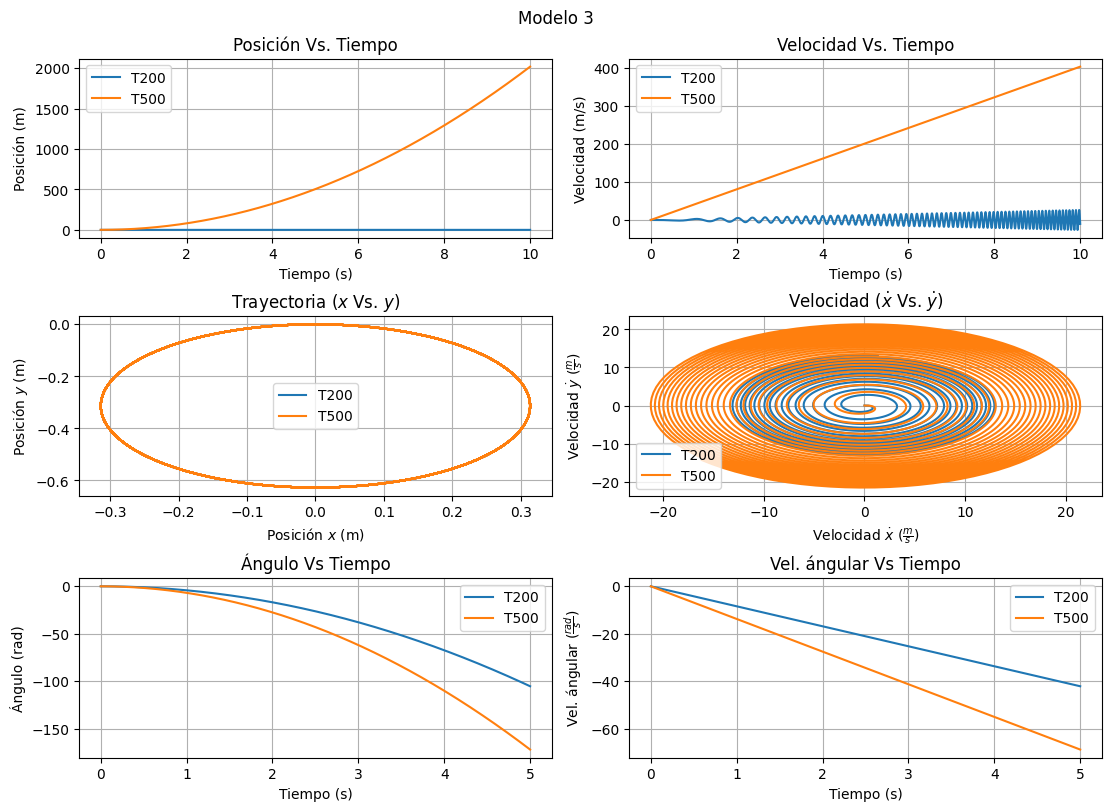

In [ ]:
fig, ax = plt.subplots(3, 2, layout='constrained', figsize=(11, 8))

fig.suptitle('Modelo 3')

ax[0,0].plot(time, q_listT200[:, 1], label='T200')
ax[0,0].plot(time, q_listT500[:, 1], label='T500')
ax[0,0].set(title='Posición Vs. Tiempo', ylabel='Posición (m)', xlabel='Tiempo (s)')
ax[0,0].legend()
ax[0,0].grid()


ax[0, 1].plot(time, q_listT200[:, 4], label='T200')
ax[0, 1].plot(time, q_listT500[:, 4], label='T500')
ax[0, 1].set(title='Velocidad Vs. Tiempo', ylabel='Velocidad (m/s)', xlabel='Tiempo (s)')
ax[0, 1].legend()
ax[0, 1].grid()

ax[1,0].plot(q_listT200_rotation[:, 0], q_listT200_rotation[:, 1], label='T200')
ax[1,0].plot(q_listT500_rotation[:, 0], q_listT500_rotation[:, 1], label='T500')
ax[1,0].set(title='Trayectoria ($x$ Vs. $y$)', xlabel='Posición $x$ (m)', ylabel='Posición $y$ (m)')
ax[1,0].legend()
ax[1,0].grid()

ax[1,1].plot(q_listT200_rotation[:, 3], q_listT200_rotation[:, 4], label='T200')
ax[1,1].plot(q_listT500_rotation[:, 3], q_listT500_rotation[:, 4], label='T500')
ax[1,1].set(title=r'Velocidad ($\dot{x}$ Vs. $\dot{y}$)', xlabel=r'Velocidad $\dot{x}$ ($\frac{m}{s}$)', ylabel=r'Velocidad $\dot{y}$ ($\frac{m}{s}$)')
ax[1,1].legend()
ax[1,1].grid()

ax[2,0].plot(time_rotation, q_listT200_rotation[:, 2], label='T200')
ax[2,0].plot(time_rotation, q_listT500_rotation[:, 2], label='T500')
ax[2,0].set(title=r'Ángulo Vs Tiempo', xlabel=r'Tiempo (s)', ylabel=r'Ángulo (rad)')
ax[2,0].legend()
ax[2,0].grid()

ax[2,1].plot(time_rotation, q_listT200_rotation[:, 5], label='T200')
ax[2,1].plot(time_rotation, q_listT500_rotation[:, 5], label='T500')
ax[2,1].set(title=r'Vel. ángular Vs Tiempo', xlabel=r'Tiempo (s)', ylabel=r'Vel. ángular ($\frac{rad}{s}$)')
ax[2,1].legend()
ax[2,1].grid()

plt.show()